###Task 1:Data Understanding and Exploration

In [23]:
import pandas as pd
import numpy as np
raw_data = pd.read_csv('G2.csv')
data = raw_data.copy()
data.head()

,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83
3,4,charmander,6,85,62.0,fire,NaN,39,52,43
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58


In [24]:
data.shape

(1351, 10)

In [25]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1351 non-null   int64  
 1   name             1351 non-null   object 
 2   height_dm        1351 non-null   int64  
 3   weight_hg        1351 non-null   int64  
 4   base_experience  1302 non-null   float64
 5   type_1           1351 non-null   object 
 6   type_2           765 non-null    object 
 7   hp               1351 non-null   int64  
 8   attack           1351 non-null   int64  
 9   defense          1351 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 105.7+ KB


In [26]:
data.isna().sum()

id                   0
name                 0
height_dm            0
weight_hg            0
base_experience     49
type_1               0
type_2             586
hp                   0
attack               0
defense              0
dtype: int64

In [27]:
data.describe()

,id,height_dm,weight_hg,base_experience,hp,attack,defense
count,1351.000000,1351.000000,1351.000000,1302.000000,1351.000000,1351.000000,1351.000000
mean,2841.692080,20.443375,991.059956,161.943932,71.673575,82.757957,76.193930
std,4139.019112,53.238467,1953.115812,82.532554,26.827529,32.351906,30.712902
min,1.000000,1.000000,0.000000,36.000000,1.000000,5.000000,5.000000
25%,338.500000,6.000000,94.500000,71.000000,55.000000,60.000000,55.000000
50%,676.000000,11.000000,326.000000,165.000000,70.000000,80.000000,70.000000
75%,1013.500000,17.000000,853.500000,222.500000,85.000000,102.500000,95.000000
max,10326.000000,1000.000000,10000.000000,608.000000,255.000000,190.000000,250.000000


In [28]:
data.drop(columns=['id'],inplace=True)
data

,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense
0,bulbasaur,7,69,64.0,grass,poison,45,49,49
1,ivysaur,10,130,142.0,grass,poison,60,62,63
2,venusaur,20,1000,236.0,grass,poison,80,82,83
3,charmander,6,85,62.0,fire,NaN,39,52,43
4,charmeleon,11,190,142.0,fire,NaN,58,64,58
...,...,...,...,...,...,...,...,...,...
1346,tatsugiri-curly-mega,6,240,NaN,dragon,water,68,65,90
1347,tatsugiri-droopy-mega,6,240,NaN,dragon,water,68,65,90
1348,tatsugiri-stretchy-mega,6,240,NaN,dragon,water,68,65,90
1349,baxcalibur-mega,21,3150,NaN,dragon,ice,115,175,117


In [29]:
no_duplicates = data.duplicated().sum()
no_duplicates

np.int64(0)

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

### Task 2: Data Preprocessing



In [31]:
# Treat the single zero weight as an invalid/missing measurement.
data.loc[data['weight_hg'].eq(0), 'weight_hg'] = np.nan
missing_before = data.isna().sum()
numeric_columns = data.select_dtypes(include=np.number).columns
data[numeric_columns] = data[numeric_columns].fillna(data[numeric_columns].median())
data['type_2'] = data['type_2'].fillna('none')
print('Missing values before preprocessing:\n', missing_before[missing_before > 0])
print('Missing values after preprocessing:', int(data.isna().sum().sum()))
data.isna().sum()

Missing values before preprocessing:
 weight_hg            1
base_experience     49
type_2             586
dtype: int64
Missing values after preprocessing: 0


name               0
height_dm          0
weight_hg          0
base_experience    0
type_1             0
type_2             0
hp                 0
attack             0
defense            0
dtype: int64

### Prepare features and create training/testing datasets



In [32]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler

target = 'type_1'
X = raw_data.drop(columns=[target, 'name', 'id']).copy()
y = raw_data[target].copy()
X.loc[X['weight_hg'].eq(0), 'weight_hg'] = np.nan

categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='none')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

# Fit preprocessing only on training data; apply the learned transform to test data.
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print('Training feature matrix:', X_train_processed.shape)
print('Testing feature matrix: ', X_test_processed.shape)
print('Training labels:        ', y_train.shape)
print('Testing labels:         ', y_test.shape)
print('Training class counts:\n', y_train.value_counts().sort_index())
print('Testing class counts:\n', y_test.value_counts().sort_index())

Training feature matrix: (1080, 25)
Testing feature matrix:  (271, 25)
Training labels:         (1080,)
Testing labels:          (271,)
Training class counts:
 type_1
bug          76
dark         50
dragon       47
electric     80
fairy        28
fighting     50
fire         67
flying       10
ghost        42
grass        97
ground       40
ice          35
normal      111
poison       42
psychic      69
rock         66
steel        42
water       128
Name: count, dtype: int64
Testing class counts:
 type_1
bug         19
dark        13
dragon      12
electric    20
fairy        7
fighting    12
fire        17
flying       3
ghost       10
grass       25
ground      10
ice          9
normal      28
poison      10
psychic     17
rock        17
steel       10
water       32
Name: count, dtype: int64


### Task 3: Exploratory Data Analysis



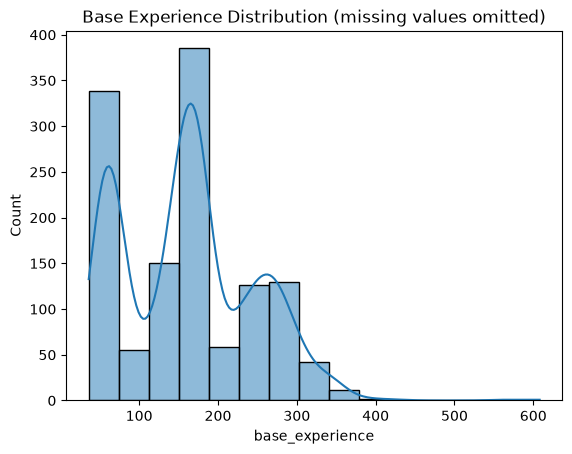

In [33]:
sns.histplot(data=raw_data, x='base_experience', bins=15, kde=True)
plt.title('Base Experience Distribution (missing values omitted)')
plt.show()

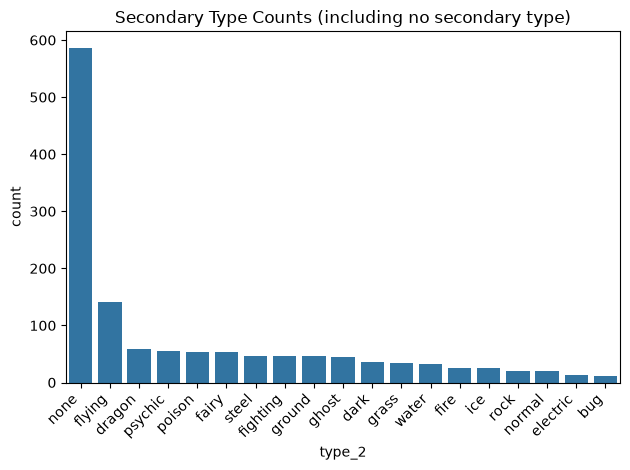

In [34]:
sns.countplot(data=data, x='type_2', order=data['type_2'].value_counts().index)
plt.title('Secondary Type Counts (including no secondary type)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

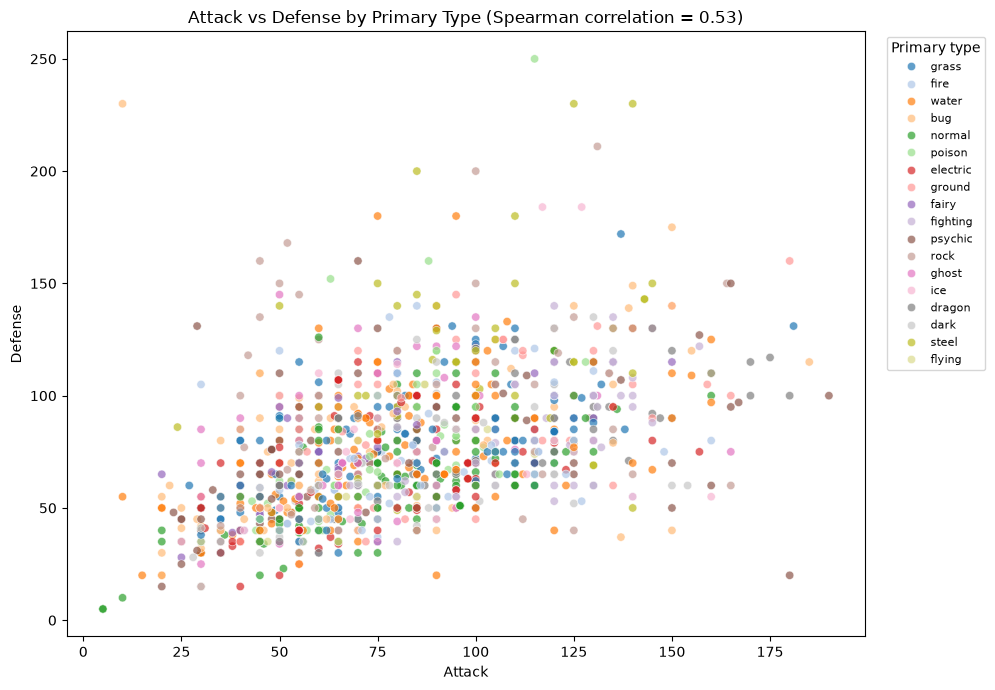

Spearman correlation between Attack and Defense: 0.529


In [35]:
attack_defense_rho = data[['attack', 'defense']].corr(method='spearman').iloc[0, 1]
plt.figure(figsize=(12, 7))
ax = sns.scatterplot(data=data, x='attack', y='defense', hue='type_1', palette='tab20', s=36, alpha=0.7)
ax.set_title(f'Attack vs Defense by Primary Type (Spearman correlation = {attack_defense_rho:.2f})')
ax.set_xlabel('Attack')
ax.set_ylabel('Defense')
ax.legend(title='Primary type', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout(rect=(0, 0, 0.84, 1))
plt.show()
print(f'Spearman correlation between Attack and Defense: {attack_defense_rho:.3f}')

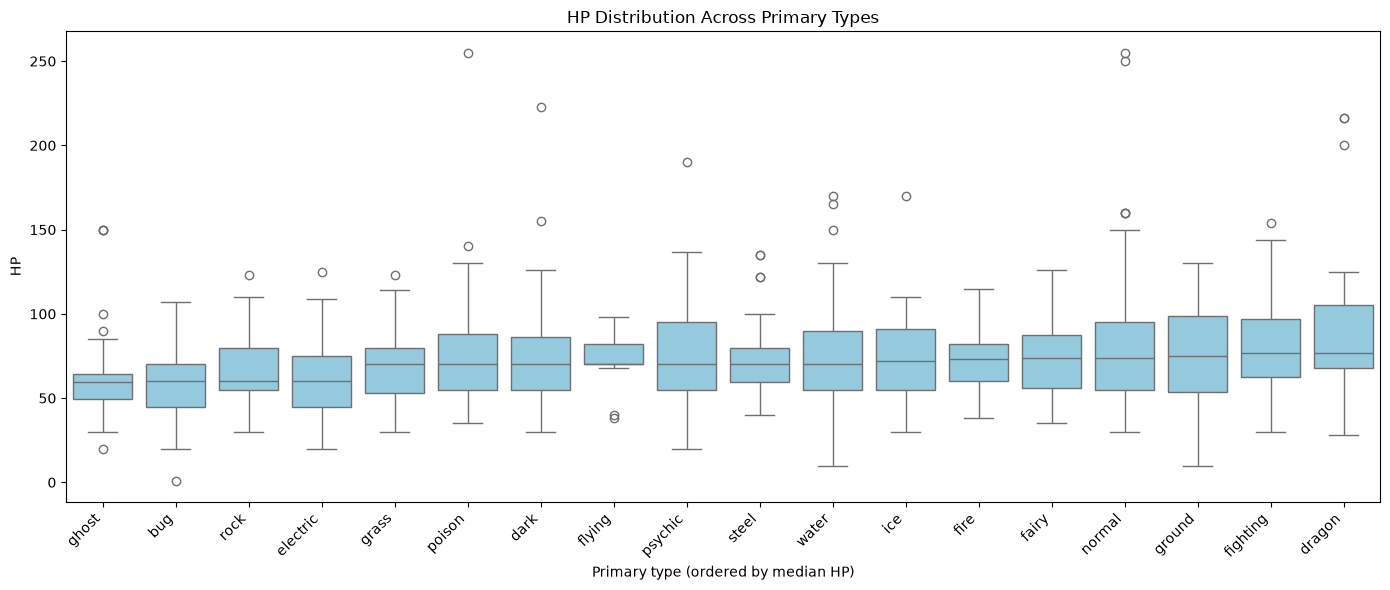

In [36]:
hp_type_order = data.groupby('type_1')['hp'].median().sort_values().index
plt.figure(figsize=(14, 6))
ax = sns.boxplot(data=data, x='type_1', y='hp', order=hp_type_order, color='skyblue')
ax.set_title('HP Distribution Across Primary Types')
ax.set_xlabel('Primary type (ordered by median HP)')
ax.set_ylabel('HP')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

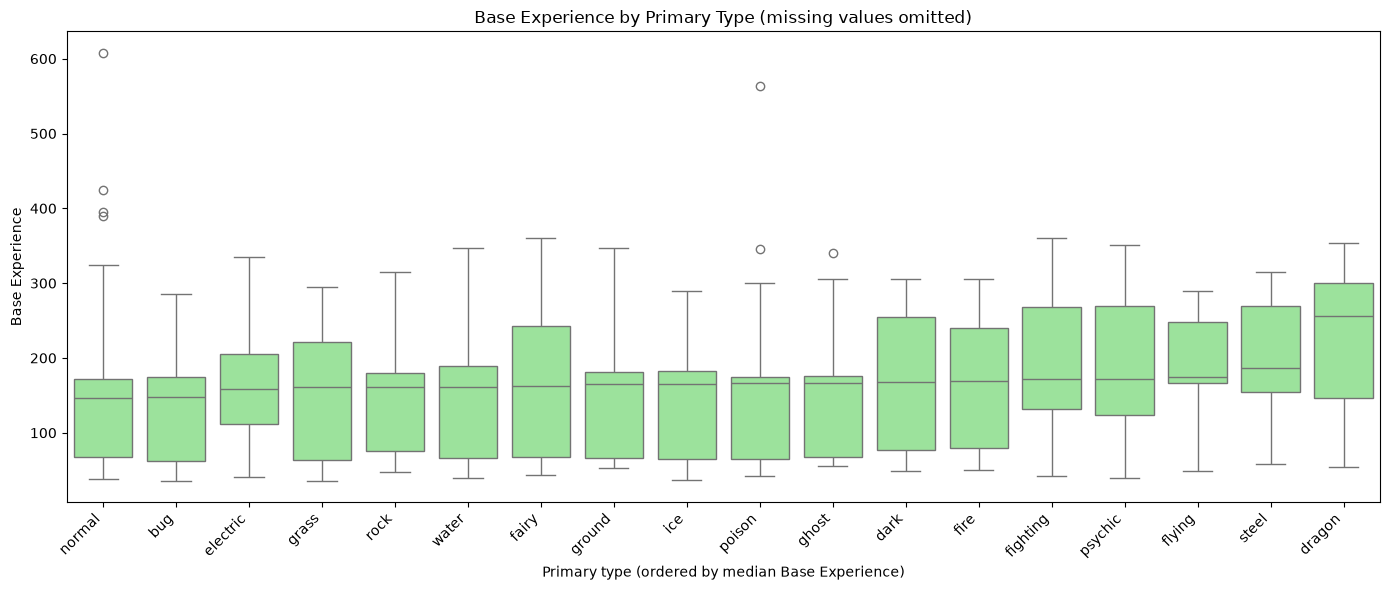

In [37]:
experience_data = raw_data.dropna(subset=['base_experience'])
experience_type_order = experience_data.groupby('type_1')['base_experience'].median().sort_values().index
plt.figure(figsize=(14, 6))
ax = sns.boxplot(data=experience_data, x='type_1', y='base_experience', order=experience_type_order, color='lightgreen')
ax.set_title('Base Experience by Primary Type (missing values omitted)')
ax.set_xlabel('Primary type (ordered by median Base Experience)')
ax.set_ylabel('Base Experience')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

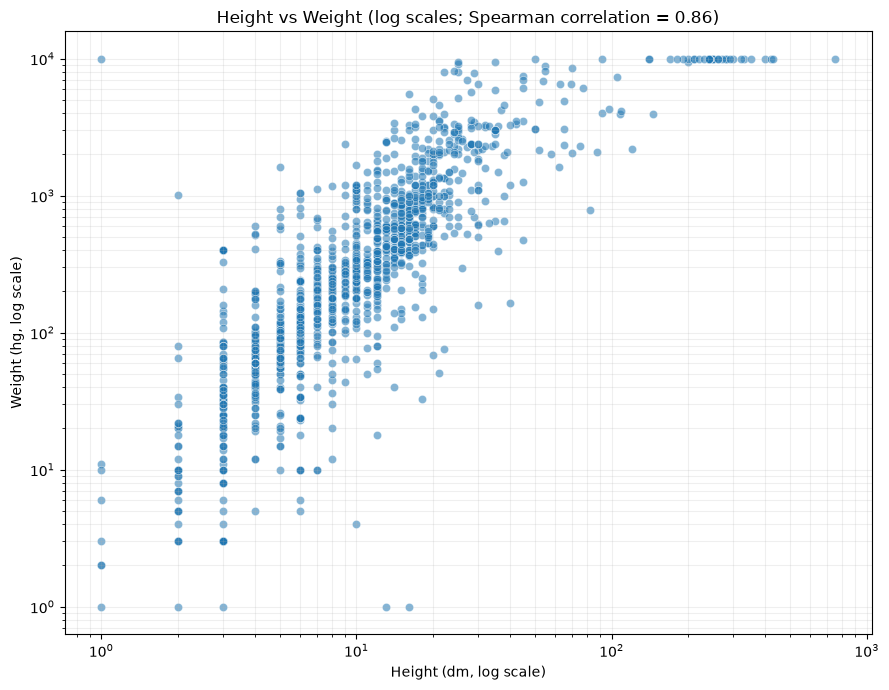

Spearman correlation between Height and Weight (positive weights): 0.857


In [38]:
height_weight_data = raw_data.loc[raw_data['weight_hg'] > 0]
height_weight_rho = height_weight_data[['height_dm', 'weight_hg']].corr(method='spearman').iloc[0, 1]
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=height_weight_data, x='height_dm', y='weight_hg', alpha=0.55, s=35, ax=ax)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(f'Height vs Weight (log scales; Spearman correlation = {height_weight_rho:.2f})')
ax.set_xlabel('Height (dm, log scale)')
ax.set_ylabel('Weight (hg, log scale)')
ax.grid(True, which='both', alpha=0.2)
plt.tight_layout()
plt.show()
print(f'Spearman correlation between Height and Weight (positive weights): {height_weight_rho:.3f}')

C:\Users\LAB-USER-01\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


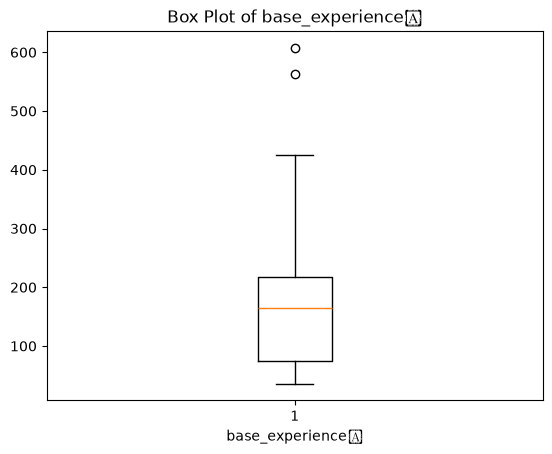

In [39]:
plt.boxplot(data['base_experience'])
plt.xlabel('base_experience	')
plt.title('Box Plot of base_experience	')
plt.show()

C:\Users\LAB-USER-01\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


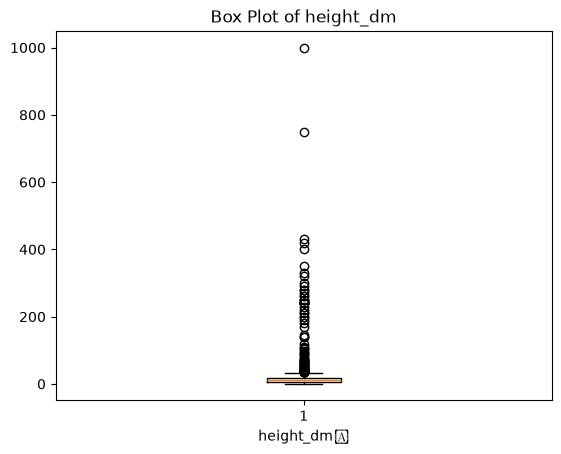

In [40]:
plt.boxplot(data['height_dm'])
plt.xlabel('height_dm	')
plt.title('Box Plot of height_dm')
plt.show()

C:\Users\LAB-USER-01\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


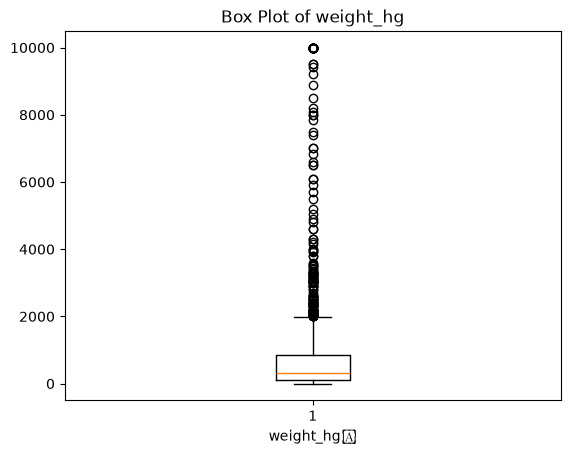

In [41]:
plt.boxplot(data['weight_hg'])
plt.xlabel('weight_hg	')
plt.title('Box Plot of weight_hg')
plt.show()

### Task 4: Machine Learning Modeling


In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

models = {
    'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced'),
    # No class weighting is used because the goal here is to improve overall accuracy.
    'Random Forest': RandomForestClassifier(
        n_estimators=400, max_features='sqrt', class_weight=None,
        random_state=42, n_jobs=-1
    ),
    'RBF SVC': SVC(kernel='rbf', class_weight='balanced'),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=7, weights='distance')
}

model_pipelines = {
    name: Pipeline(steps=[('preprocessor', preprocessor), ('classifier', estimator)])
    for name, estimator in models.items()
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
evaluation_rows = []
for name, pipeline in model_pipelines.items():
    cv_accuracy = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='accuracy').mean()
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    evaluation_rows.append({
        'Model': name,
        'CV Accuracy': cv_accuracy,
        'Test Accuracy': accuracy_score(y_test, predictions),
        'Precision (macro)': precision_score(y_test, predictions, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_test, predictions, average='macro', zero_division=0),
        'F1 (macro)': f1_score(y_test, predictions, average='macro', zero_division=0),
        'F1 (weighted)': f1_score(y_test, predictions, average='weighted', zero_division=0)
    })

results = pd.DataFrame(evaluation_rows).sort_values(
    ['CV Accuracy', 'Test Accuracy'], ascending=False
).reset_index(drop=True)
display(results.round(3))
best_model_name = results.loc[0, 'Model']
best_model = model_pipelines[best_model_name]
best_predictions = best_model.predict(X_test)
print(f"Selected model by cross-validation accuracy: {best_model_name}")
print(f"Held-out test accuracy: {results.loc[0, 'Test Accuracy']:.3f}")

C:\Users\LAB-USER-01\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\LAB-USER-01\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\LAB-USER-01\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\LAB-USER-01\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Model,CV Accuracy,Test Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
0,Random Forest,0.281,0.299,0.313,0.247,0.249,0.285
1,K-Nearest Neighbors,0.217,0.236,0.248,0.208,0.218,0.235
2,Logistic Regression,0.179,0.155,0.139,0.164,0.138,0.140
3,RBF SVC,0.110,0.177,0.160,0.194,0.158,0.152


Selected model by cross-validation accuracy: Random Forest
Held-out test accuracy: 0.299


#### Best model: confusion matrix




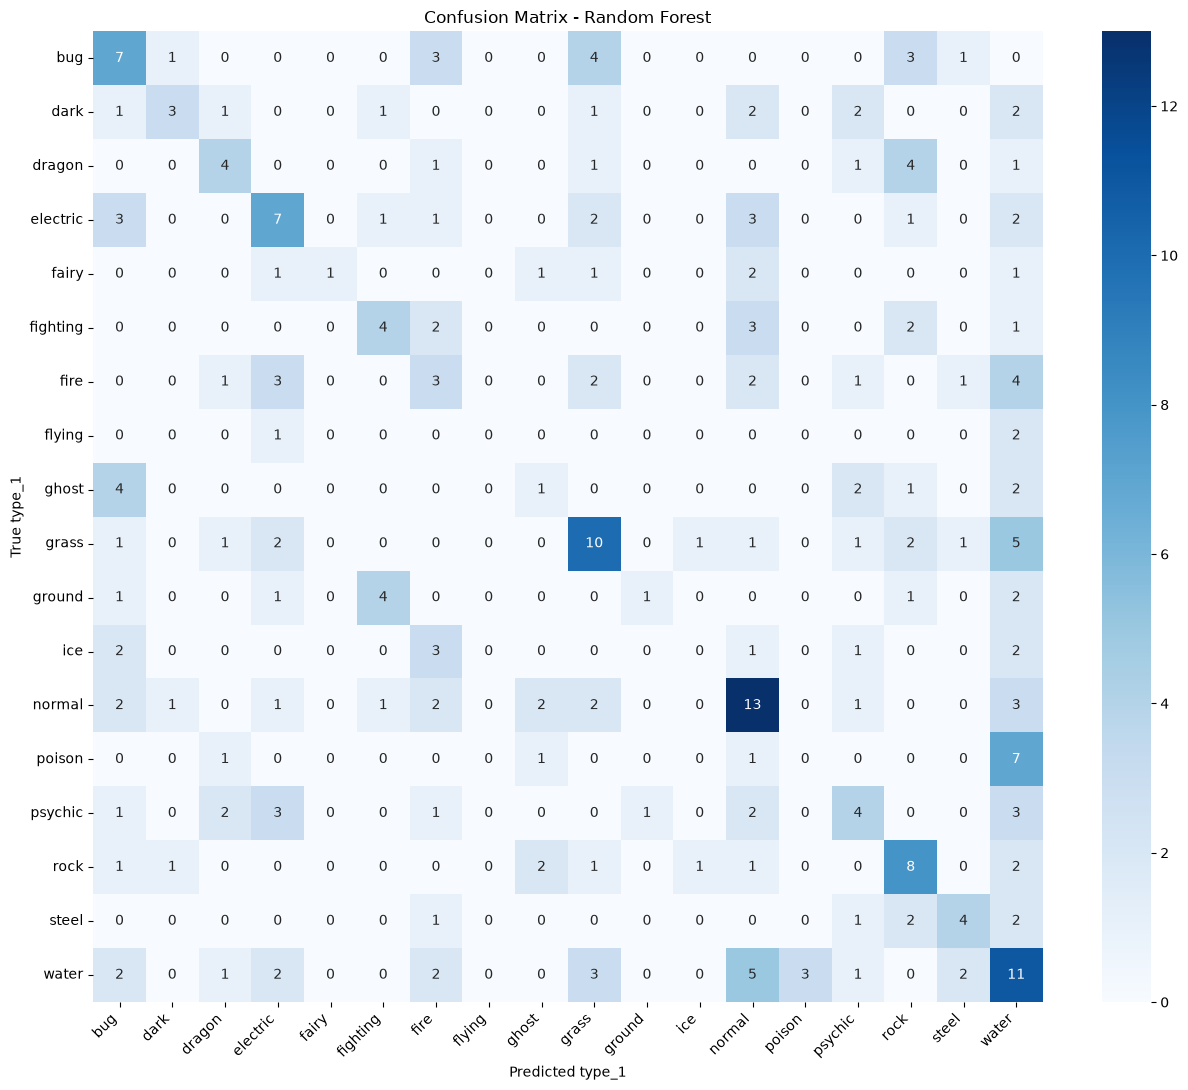

In [43]:
from sklearn.metrics import confusion_matrix

class_labels = sorted(y.unique())
matrix = confusion_matrix(y_test, best_predictions, labels=class_labels)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels, ax=ax)
ax.set_title(f'Confusion Matrix - {best_model_name}')
ax.set_xlabel('Predicted type_1')
ax.set_ylabel('True type_1')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### Most influential feature



,Feature,Mean accuracy decrease,Standard deviation
0,type_2,0.0683,0.0160
1,hp,0.0653,0.0152
2,base_experience,0.0587,0.0085
3,defense,0.0528,0.0163
4,height_dm,0.0310,0.0172
5,attack,0.0310,0.0136
6,weight_hg,0.0292,0.0127


Most influential feature for Random Forest: type_2 (mean accuracy decrease = 0.0683)


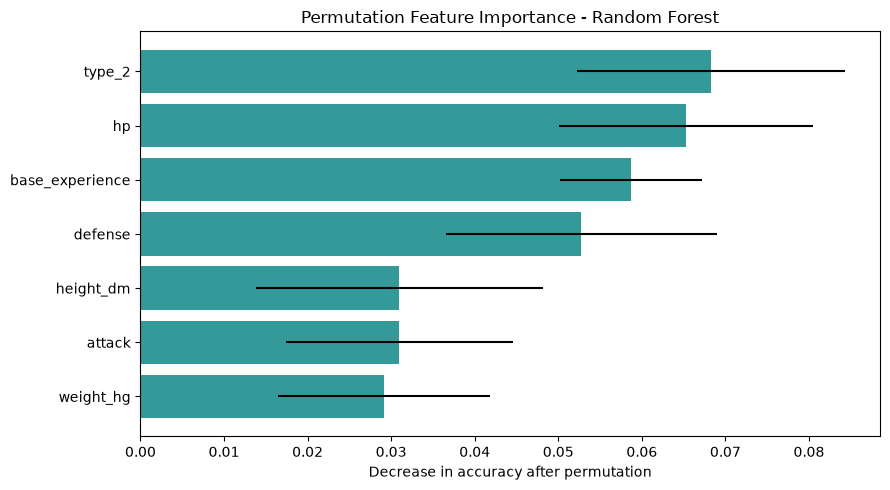

In [44]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    best_model, X_test, y_test, scoring='accuracy', n_repeats=10, random_state=42, n_jobs=-1
)
feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean accuracy decrease': permutation_result.importances_mean,
    'Standard deviation': permutation_result.importances_std
}).sort_values('Mean accuracy decrease', ascending=False).reset_index(drop=True)
display(feature_importance.round(4))
top_feature = feature_importance.iloc[0]['Feature']
print(f"Most influential feature for {best_model_name}: {top_feature} (mean accuracy decrease = {feature_importance.iloc[0]['Mean accuracy decrease']:.4f})")

plot_data = feature_importance.sort_values('Mean accuracy decrease')
plt.figure(figsize=(9, 5))
plt.barh(plot_data['Feature'], plot_data['Mean accuracy decrease'], xerr=plot_data['Standard deviation'], color='teal', alpha=0.8)
plt.xlabel('Decrease in accuracy after permutation')
plt.title(f'Permutation Feature Importance - {best_model_name}')
plt.tight_layout()
plt.show()